# Model 4 - XGBoost (Member 4)

XGBoost builds many small trees one after another, each correcting the errors of the previous ones (gradient boosting). It is usually the strongest tabular model but needs careful tuning to avoid overfitting.

## 1. Load the final tables

The tables come from Section 11 of the main notebook (`ML_code.ipynb`): time-based split (train = 2008/09-2013/14, test = 2014/15-2015/16), engineered features, no leakage columns.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd, numpy as np, json, warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

# Define the correct path to Google Drive directory
drive_path = "/content/drive/MyDrive/Y3S1/Assignment/Models/"

# Final tables produced by the feature-engineering notebook
train      = pd.read_csv(drive_path + "train_final.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test       = pd.read_csv(drive_path + "test_final.csv", parse_dates=["date"])
train_odds = pd.read_csv(drive_path + "train_final_odds.csv", parse_dates=["date"]).sort_values(["date", "match_api_id"])
test_odds  = pd.read_csv(drive_path + "test_final_odds.csv", parse_dates=["date"])
feats = json.load(open(drive_path + "final_feature_sets.json"))

# Two experiments: our own features only, and our features + bookmaker odds
experiments = {
    "No odds":   (train,      test,      feats["features_no_odds"]),
    "With odds": (train_odds, test_odds, feats["features_with_odds"]),
}
class_names = ["Away win", "Draw", "Home win"]      # target: 0 = A, 1 = D, 2 = H
for name, (tr, te, cols) in experiments.items():
    print(f"{name:10s} train {tr.shape[0]:6d} | test {te.shape[0]:5d} | features {len(cols)}")

No odds    train  19328 | test  6651 | features 16
With odds  train  16783 | test  5809 | features 18


## 2. Evaluation helper

The test set is used **only once**, after tuning. Metrics: accuracy, macro F1 (main metric), weighted F1, log loss and draw recall.

In [ ]:
def evaluate(model, X, y, label, exp):
    """Test-set metrics. Macro F1 is the main metric because draws are the hardest class."""
    pred = model.predict(X)
    proba = model.predict_proba(X) if hasattr(model, "predict_proba") else None
    report = classification_report(y, pred, output_dict=True, zero_division=0)
    return {"model": label, "features": exp,
            "accuracy": round(accuracy_score(y, pred), 4),
            "macro_F1": round(f1_score(y, pred, average="macro"), 4),
            "weighted_F1": round(f1_score(y, pred, average="weighted"), 4),
            "log_loss": round(log_loss(y, proba), 4) if proba is not None else np.nan,
            "draw_recall": round(report["1"]["recall"], 4)}

def show_confusion(model, X, y, title):
    ConfusionMatrixDisplay.from_predictions(y, model.predict(X), display_labels=class_names, cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()

## 3. Tune and train the XGBoost

Shallow trees (`max_depth` 2-4) and a small `learning_rate` make boosting more cautious. Sample weights balance the classes.

Hyper-parameters are tuned with `GridSearchCV` and `TimeSeriesSplit` **inside the training data only** (each fold validates on a later period than it trains on), scored by macro F1.

No odds | best parameters: {'learning_rate': 0.03, 'max_depth': 2} | CV macro F1: 0.4306


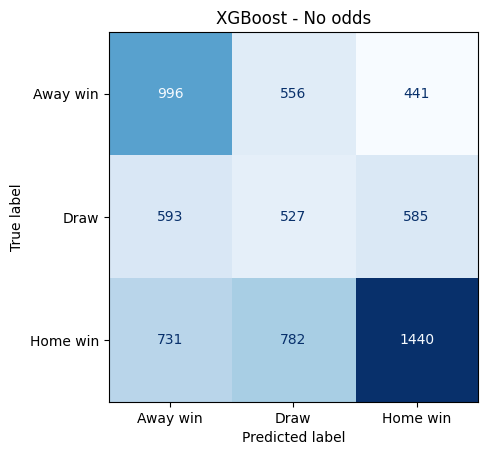

With odds | best parameters: {'learning_rate': 0.03, 'max_depth': 2} | CV macro F1: 0.4651


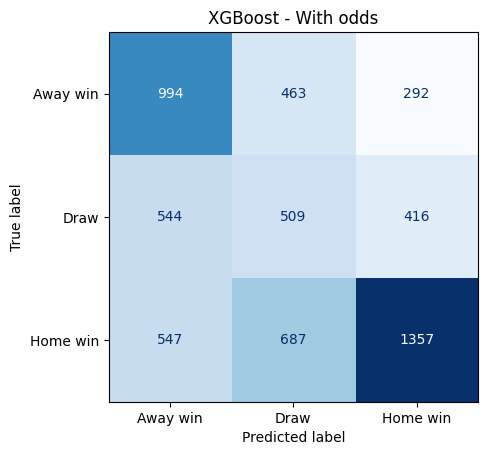

In [ ]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

model = XGBClassifier(objective='multi:softprob', n_estimators=150, subsample=0.8, colsample_bytree=0.8,
                      eval_metric='mlogloss', random_state=42, n_jobs=-1)
grid = {'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.1]}

results, best_models = [], {}
cv = TimeSeriesSplit(n_splits=3)

for exp, (tr, te, cols) in experiments.items():
    X_tr, y_tr, X_te, y_te = tr[cols], tr["target"], te[cols], te["target"]
    weights = compute_sample_weight("balanced", y_tr)      # gives Away / Draw more weight (XGBoost has no class_weight option)
    search = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=1)
    search.fit(X_tr, y_tr, sample_weight=weights)
    best_models[exp] = search.best_estimator_
    print(exp, "| best parameters:", search.best_params_, "| CV macro F1:", round(search.best_score_, 4))
    results.append(evaluate(search.best_estimator_, X_te, y_te, "XGBoost", exp))
    show_confusion(search.best_estimator_, X_te, y_te, f"XGBoost - {exp}")

## 4. Results on the test seasons (2014/15 - 2015/16)

In [ ]:
results_table = pd.DataFrame(results)
results_table.to_csv("results_04_xgboost.csv", index=False)
results_table

,model,features,accuracy,macro_F1,weighted_F1,log_loss,draw_recall
0,XGBoost,No odds,0.4455,0.4295,0.4500,1.0451,0.3091
1,XGBoost,With odds,0.4923,0.4756,0.4984,0.9999,0.3465


## 5. Interpretation of the model

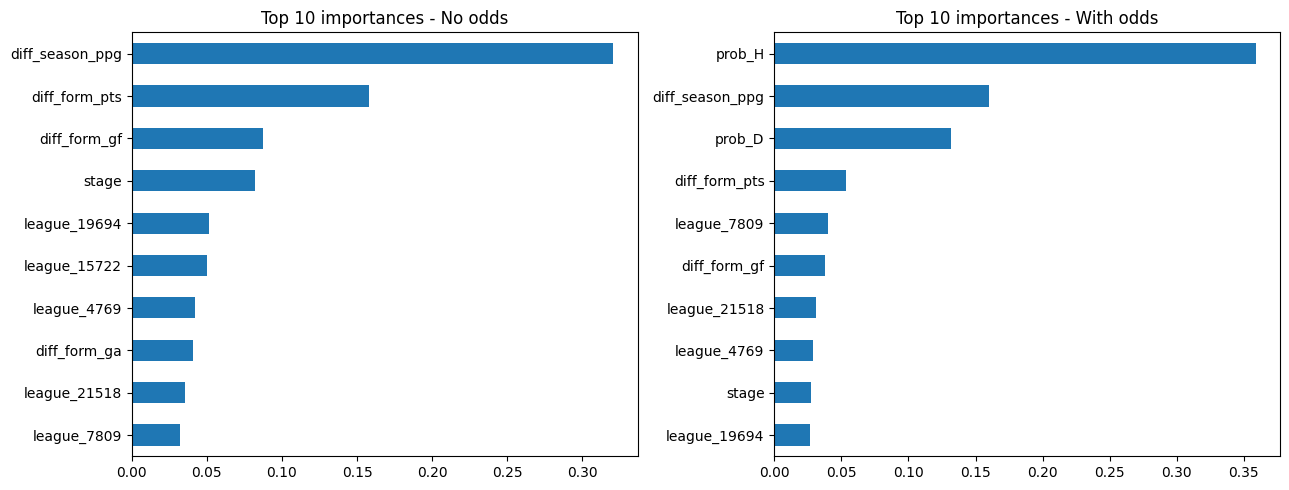

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (exp, (tr, te, cols)) in zip(axes, experiments.items()):
    imp = pd.Series(best_models[exp].feature_importances_, index=cols).sort_values().tail(10)
    imp.plot(kind="barh", ax=ax, title=f"Top 10 importances - {exp}")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files
files.download('results_04_xgboost.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>